# Phase 11.2 - Reward shaping + input enriquecido

Búsqueda de trials con features temporales enriquecidas, reward shaping y política híbrida por ventaja Q.

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
SCRIPT = ROOT / 'phases/phase11_offline_rl/run_phase11_2_offline_rl_reward_input.py'

res = subprocess.run(['python', str(SCRIPT)], cwd=ROOT, check=True, capture_output=True, text=True)
print(res.stdout)
if res.stderr:
    print(res.stderr)


Saved summary: ./phases/phase11_offline_rl/output_phase11_2_offline_rl_reward_input_GBPUSD/GBPUSD_phase11_2_summary.json
Best trial: t4_shaped_scale
Holdout metrics: {'behavior': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00016313956810976485, 'cum_net_return': 0.5866498869227144, 'std_net_return': 0.004038152876353244, 'trade_rate': 0.3604004383087158, 'sharpe_ann': 3.14182826856007, 'win_rate_trades': 0.5478395061728395}, 'bc': {'acc_action_3': 0.29588431590656283, 'f1_macro_action_3': 0.2789283351459753, 'avg_net_return': 4.1368500041465816e-05, 'cum_net_return': 0.14876112614911108, 'std_net_return': 0.0034948335008891255, 'trade_rate': 0.5058398246765137, 'sharpe_ann': 0.9205538004802619, 'win_rate_trades': 0.4964266080263881}, 'cql': {'acc_action_3': 0.2360956618464961, 'f1_macro_action_3': 0.21551815463195892, 'avg_net_return': 6.857994243079891e-05, 'cum_net_return': 0.24661347298115288, 'std_net_return': 0.00286029054801

In [2]:
import json
import pandas as pd
from IPython.display import display

OUT = ROOT / 'phases/phase11_offline_rl/output_phase11_2_offline_rl_reward_input_GBPUSD'
summary = json.loads((OUT / 'GBPUSD_phase11_2_summary.json').read_text())
trials = pd.read_csv(OUT / 'GBPUSD_phase11_2_trials.csv')
compare = pd.read_csv(OUT / 'GBPUSD_phase11_2_policy_comparison.csv')

print('Best trial:', summary['best_trial'])
print('Holdout metrics:', summary['holdout_metrics'])
print('Trials ranking:')
display(trials.sort_values('val_score_hybrid', ascending=False))
print('Policy comparison:')
display(compare)


Best trial: {'name': 't4_shaped_scale', 'hidden_dim': 128, 'cql_alpha': 1.4, 'bc_reg': 0.01, 'q_lr': 0.0007, 'q_epochs': 60, 'turnover_penalty_mult': 1.0, 'reward_scale': 1.5}
Holdout metrics: {'behavior': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00016313956810976485, 'cum_net_return': 0.5866498869227144, 'std_net_return': 0.004038152876353244, 'trade_rate': 0.3604004383087158, 'sharpe_ann': 3.14182826856007, 'win_rate_trades': 0.5478395061728395}, 'bc': {'acc_action_3': 0.29588431590656283, 'f1_macro_action_3': 0.2789283351459753, 'avg_net_return': 4.1368500041465816e-05, 'cum_net_return': 0.14876112614911108, 'std_net_return': 0.0034948335008891255, 'trade_rate': 0.5058398246765137, 'sharpe_ann': 0.9205538004802619, 'win_rate_trades': 0.4964266080263881}, 'cql': {'acc_action_3': 0.2360956618464961, 'f1_macro_action_3': 0.21551815463195892, 'avg_net_return': 6.857994243079891e-05, 'cum_net_return': 0.24661347298115288, 'std_ne

,trial,hidden_dim,cql_alpha,bc_reg,q_lr,q_epochs,turnover_penalty_mult,reward_scale,val_score_hybrid,val_avg_hybrid,val_sharpe_hybrid,holdout_cum_hybrid,holdout_cum_behavior,holdout_cum_bc,holdout_cum_cql,hyb_conf_thr,hyb_adv_thr,hyb_inf_min
4,t4_shaped_scale,128,1.4,0.01,0.0007,60,1.0,1.5,3.052058,0.000266,3.872922,0.570493,0.58665,0.148761,0.246613,0.45,0.196041,0.5
0,t0_ref,128,1.2,0.02,0.0008,50,0.0,1.0,3.012073,0.000263,3.826223,0.585980,0.58665,0.501623,0.278834,0.75,0.000000,0.3
1,t1_turnover_light,128,1.0,0.02,0.0008,55,0.5,1.0,3.006994,0.000263,3.804570,0.590262,0.58665,0.247091,0.223423,0.65,0.000000,0.3
2,t2_turnover_med,128,1.2,0.01,0.0008,55,1.0,1.0,2.980661,0.000260,3.797042,0.575092,0.58665,0.479655,0.281989,0.75,0.000000,0.3
3,t3_wider,160,1.0,0.01,0.0007,60,0.5,1.0,2.769897,0.000241,3.607612,0.616326,0.58665,0.317372,0.362460,0.45,0.000000,0.3


Policy comparison:


,split,policy,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,trade_rate,sharpe_ann,win_rate_trades
0,validation,behavior,0.337427,0.332445,0.000228,0.390024,0.005181,0.361988,3.423678,0.531502
1,validation,bc,0.264912,0.246231,0.000238,0.407036,0.004863,0.200585,3.806257,0.551020
2,validation,cql,0.224561,0.188794,0.000317,0.541781,0.004356,0.105263,5.656002,0.611111
3,validation,hybrid_advantage,0.339766,0.335406,0.000266,0.455675,0.005351,0.370175,3.872922,0.532385
4,holdout,behavior,0.326196,0.324551,0.000163,0.586650,0.004038,0.360400,3.141828,0.547840
5,holdout,bc,0.295884,0.278928,0.000041,0.148761,0.003495,0.505840,0.920554,0.496427
6,holdout,cql,0.236096,0.215518,0.000069,0.246613,0.002860,0.180756,1.864631,0.536923
7,holdout,hybrid_advantage,0.343993,0.342459,0.000159,0.570493,0.004166,0.406285,2.961714,0.539357


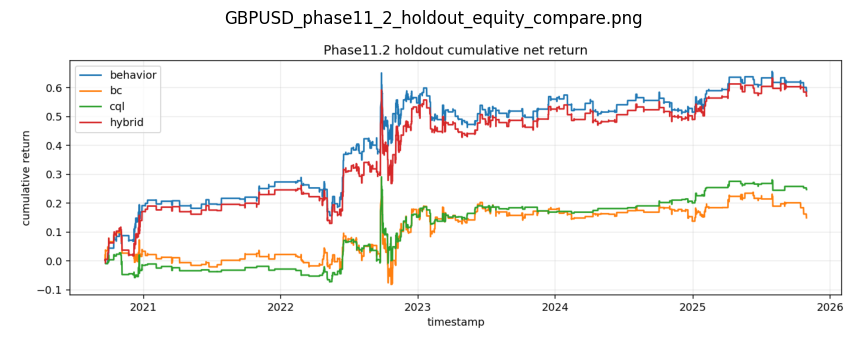

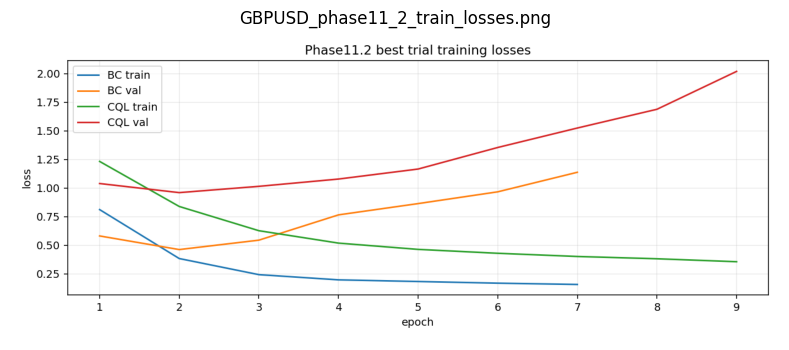

In [3]:
import matplotlib.pyplot as plt
img1 = plt.imread(OUT / 'GBPUSD_phase11_2_holdout_equity_compare.png')
img2 = plt.imread(OUT / 'GBPUSD_phase11_2_train_losses.png')

plt.figure(figsize=(12, 4))
plt.imshow(img1)
plt.axis('off')
plt.title('GBPUSD_phase11_2_holdout_equity_compare.png')
plt.show()

plt.figure(figsize=(12, 4))
plt.imshow(img2)
plt.axis('off')
plt.title('GBPUSD_phase11_2_train_losses.png')
plt.show()
